# MECHA, 3: combine parameters

**What you will learn:** solve MECHA on a grid of values of two parameters, gather the results in one table, and see
how the two act together.

**You need:** tutorial 2. **Run time:** about 15 seconds.

## 1. Walls against aquaporins

Water crosses the cortex mostly along the walls (`kw`), and the endodermis mostly through the membranes, helped by
the aquaporins (`kaqp`). Both are varied from a tenth to ten times their default: 9 solves.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.mecha.simulation import simulate

factors = [0.1, 1., 10.]
rows = []
for kw_factor, kaqp_factor in itertools.product(factors, factors):
    summary = simulate({"kw": 2.4e-4 * kw_factor, "kaqp": 4.3e-4 * kaqp_factor}).summary
    rows.append({"kw ×": kw_factor, "kaqp ×": kaqp_factor, **summary})
grid = pd.DataFrame(rows)
grid[["kw ×", "kaqp ×", "kr", "cortex_wall_share", "cortex_membrane_share"]].round(5)

,kw ×,kaqp ×,kr,cortex_wall_share,cortex_membrane_share
0,0.1,0.1,0.00003,0.84440,0.04436
1,0.1,1.0,0.00005,0.71817,0.19031
2,0.1,10.0,0.00017,0.33165,0.62651
3,1.0,0.1,0.00004,0.95682,0.01770
4,1.0,1.0,0.00011,0.95145,0.03534
5,1.0,10.0,0.00038,0.79099,0.19850
6,10.0,0.1,0.00005,0.96799,0.01638
7,10.0,1.0,0.00014,0.98342,0.01407
8,10.0,10.0,0.00080,0.96463,0.03408


## 2. Read the table as maps

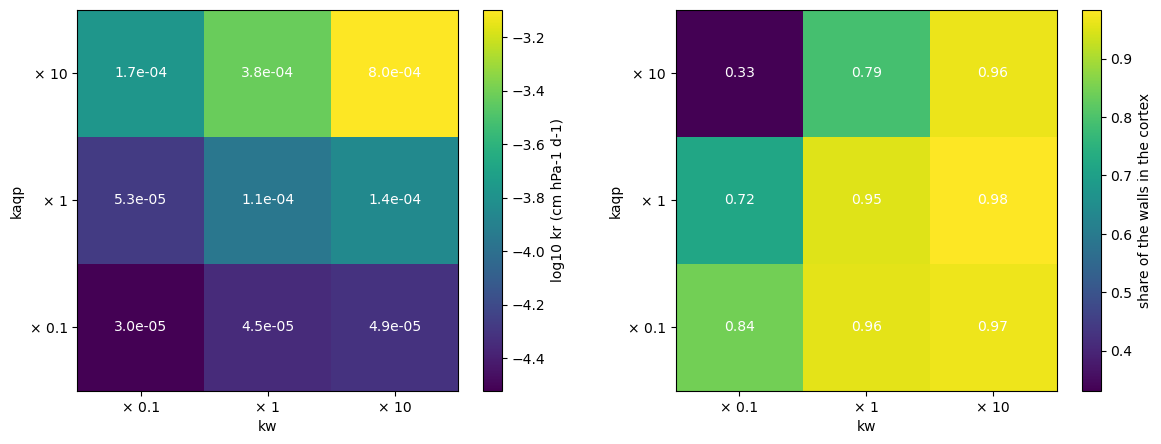

In [2]:
kr = grid.pivot(index="kaqp ×", columns="kw ×", values="kr")
wall_share = grid.pivot(index="kaqp ×", columns="kw ×", values="cortex_wall_share")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, table, label, text in ((axes[0], np.log10(kr), "log10 kr (cm hPa-1 d-1)", "{:.1e}"),
                               (axes[1], wall_share, "share of the walls in the cortex", "{:.2f}")):
    image = ax.imshow(table.values, origin="lower", cmap="viridis")
    ax.set_xticks(range(3), [f"× {f:g}" for f in factors]); ax.set_xlabel("kw")
    ax.set_yticks(range(3), [f"× {f:g}" for f in factors]); ax.set_ylabel("kaqp")
    values = kr.values if ax is axes[0] else wall_share.values
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, text.format(value), ha="center", va="center", color="w")
    fig.colorbar(image, ax=ax, label=label)
plt.tight_layout()

**Reading the maps.**

- **kr** grows with both, but not alike. With few aquaporins (bottom row), the endodermis' membranes limit
  everything: more conductive walls barely help. With many aquaporins (top row), the walls of the cortex become
  the limit, and `kw` matters.
- **The wall share** in the cortex depends on the balance between the two. Conductive walls and few aquaporins send
  almost all the water along the walls. Poor walls and many aquaporins send much of it through the cells.

That is an **interaction**: the effect of one parameter depends on the value of the other. Changing one parameter
at a time would not show it.

## Try it yourself

1. Replace `kw` by `kpl` (the plasmodesmata). Does it interact with `kaqp`?
2. Repeat the grid with a suberized endodermis (`simulate(..., barrier=3)`). What limits kr now?

**Next:** `04_sensitivity_analysis.ipynb`.